# HypNetPerturb — perturbation simulation analysis (notebook version)

This notebook reproduces the analysis pipeline implemented in `main_TargetScores-np-nG.py` and `plot_TargetScoresXmag.py`, that has been used to produce the results published in *: 

*Longhena, A., Guillemaud, M., & Chavez, M. (2024). Detecting local perturbations of networks in a latent hyperbolic embedding space. Chaos: An Interdisciplinary Journal of Nonlinear Science, 34(6).

- choice of a particular random graph model and generation of n_G synthetic samples OR choice of n_G samples from real data
- embedding of the networks in hyperbolic latent space
- generation of n_p random perturbatons on the samples
- computation of metrics/scores to quantify perturbation effect on local connectivity. Metric metrics/kNdist_scores.py and metrics/dist_scores.py were used in the paper*

target: node to which the perturbation is applied
target 2 / target NN: order 2 target nodes i.e. nearest topological neighbors of the target node
baseline: average global score

--> we statistically compare the geometric perturbation scores evaluated at the target nodes and target 2 nodes with the baseline, to test the hypothesis that the presented scores are able to localize the perturbation, detecting it from geometric displacement.

--> we investigate the dependency of the localization power on particular featires of the target node: degree, clustering, ...

## 0. Imports and dependencies

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import networkx as nx
import random
import plotly.express as px
import scipy.special as scispe
import seaborn as sns
import plotly.figure_factory as ff
import pickle
from IPython.display import clear_output
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import mat73
from pathlib import Path
import plotly.io as pio
pio.renderers.default = "vscode"
import scipy.stats as st 

from hypnetperturb.utils import *
from hypnetperturb.embedding.coalescent_embedding import *
from hypnetperturb.embedding.distance import *
from hypnetperturb.visualization import *
from hypnetperturb.metrics.kNdist_score import *
from hypnetperturb.perturb_network import *
from hypnetperturb.generate_network import *

ROOT = Path().resolve().parent

## 1. Configuration

Set the model / dataset, embedding parameters, and output folders.

- `model` can be a synthetic generator label (e.g., `WattsStrogatz`, `ErdosRenyi`, `BarabasiAlbert`) or a real dataset tag (here: `real-epi`).
- `embedding_parameters_dict` contains *more* parameters than needed by some embedding functions; prefer passing dictionaries as `**kwargs` rather than converting them to a NumPy array.

In [20]:
# model: WattsStrogatz/ErdosRenyi/BarabasiAlbert
model = "WattsStrogatz"

# Domain: degree/clustering
domain = 'degree'

# number of graph realisations
n_G = 3
   
DATA_DIR = ROOT.parent / "hypnetperturb" / "data" / "epiSurg"
files_dict = n_files_from_folder(DATA_DIR, n_G)

# Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':8,
'beta_r':0.8,
'weight_r':False,
'res_dict':True
}

# number of NN to take into account
k = 10

# Create if not existing
OUTPUT_DIR = ROOT / "output"
MEDIA_DIR  = ROOT / "media"
OUTPUT_DIR.mkdir(exist_ok=True)
MEDIA_DIR.mkdir(exist_ok=True)

# output folders
output_folder = 'HypNetPerturb/output'
media_folder = 'HypNetPerturb/media'

# Magnitudes of perturbation
mag_arr = np.array([20/100, 40/100, 60/100, 80/100])
alpha_dict = assign_alpha_dict(model,mag_arr)

mag = mag_arr[2]

## Generate n_G networks
graphs = {}
degrees = {}
clusterings = {}
clusterings_int1 = {}
clusterings_int2 = {}
scores={}

for i in range(n_G):

    if model=='real-epi':

        file = files_dict[i]
        data_dict = mat73.loadmat(file)
        A = data_dict['surgicallyNaive']#['control']
        A[np.where(np.isnan(A))]=0
        graphs[i] = nx.from_numpy_array(A)

    else: graphs[i] = generate_network(model)

    N = nx.number_of_nodes(graphs[i])

    degrees[i] = np.array(list(nx.degree(graphs[i])))[:,1]
    clusterings[i] = np.array([val for val in nx.clustering(graphs[i]).values()])
    clusterings_int1[i] = (np.round(clusterings[i],1)*10**2).astype('int')
    clusterings_int2[i] = (np.round(clusterings[i],2)*10**2).astype('int')  #clustering values approximate to the second decimal and multiplied for 10**2 to give a int value, to classify nodes based on their clustering
    scores[i] = {i:np.array([]) for i in range(N)} 

degrees_unique_union = np.unique([degrees[i] for i in range(n_G)]) # union of degree classes across all graphs
clusterings_int2_unique_union = np.unique([clusterings_int2[i] for i in range(n_G)])
clusterings_int1_unique_union = np.unique([clusterings_int1[i] for i in range(n_G)])

error: no model with this name was assigned an alpha dict


In [21]:
## Determine number of perturbations to apply
k_avg = np.average(degrees[0]).astype('int') # take one of the graphs to determine k_avg, since it is approximately the same for all the graphs
print('k average =',k_avg)
km = np.round(k_avg*mag).astype('int')
a_p = scispe.binom(k_avg, km) # mean field estimate of the number of possible perturbations per node
print('a_p =',a_p)
alpha = alpha_dict[mag] # we sample the order of a fraction alpha of all the possible permutations
n_p = round(a_p*alpha*N)
print('n_p =',n_p)
n_t = n_p*n_G #total number of perturbations
print('n_t =',n_t)

n_t = 1000 # fixed for PSO

k average = 20
a_p = 125970.0
n_p = 945
n_t = 2835


## 2. Sanity check: one perturbation on one graph

This quick test:
1. Applies one perturbation to a selected graph
2. Computes node-wise kNHD scores between original and perturbed embeddings

Use this section to debug embeddings and distance computations before launching the full loop.

In [22]:
### test:  1 perturbation over 1 graph
# perturbation
G_p, nodes_p_dict = perturbation_disconnection_NT(graphs[0],mag_arr[0],1,target='random')

# compute scores between the perturbed and original graph
NHD_score_GGp = two_nets_kNHD_score(graphs[0],G_p,k,**embedding_parameters_dict)

#colors
colors = np.array(N*["blue"])
colors_legend = np.array(N*['unperturbed'])
## here instead we plot in color the nodes that are voing to be target of the perturbation
#plot original net
colors[nodes_p_dict['nodes_perturbed']]='red'
colors_legend[nodes_p_dict['nodes_perturbed']]='perturbed'
colors[nodes_p_dict['nodes_perturbed_2']]='green'
colors_legend[nodes_p_dict['nodes_perturbed_2']]='perturbed_2'
colors_list = list(colors)

#plot NHD scores in histogram
height = NHD_score_GGp
bars = np.arange(N)
x_pos = np.arange(len(bars))
df = pd.DataFrame({'%sNHD score'%k:height, 'node label':bars, 'target colors':colors_legend})
fig = px.bar(df, x='node label', y='%sNHD score'%k, color='target colors')
fig.show()

print(nodes_p_dict['nodes_perturbed'])
print(nodes_p_dict['nodes_perturbed_2'])
print(NHD_score_GGp[nodes_p_dict['nodes_perturbed']])

[np.int64(9)]
[  1   7  18 145]
[11.2636237]


## 3. Main loop: `n_p` perturbations × `n_G` graphs

This is the core experiment:
- For each graph realisation, apply many perturbations (typically disconnections)
- Compute node-wise scores for each perturbation
- Accumulate results by node attribute classes (degree / clustering, depending on `domain`)

Depending on `n_t`, this can take time. Start with small `n_t` to validate.

In [23]:
### Loop over n_p perturbations x n_G graphs

degree_target_arr = []
clustering_target_arr = []
score_global_avg_arr = []
score_target_arr = []
score_target_norm_arr = []
score_target2_avg_arr = []
score_target2_avg_norm_arr = []

for p in range(n_t):

    print("perturbation %i of %i"%(p,n_t))
    
    # RANDOM CHOSE a GRAPH
    ind_G = random.randint(0,n_G-1)
    G = graphs[ind_G]
    
    if domain == 'degree':

        # RANDOM CHOSE a DEGREE uniformly among the unique degrees
        degrees_G = degrees[ind_G]
        degrees_unique_G = np.unique(degrees_G)
        d_ind = random.randint(0,len(degrees_unique_G)-1) 
        d = degrees_unique_G[d_ind] #corresponding degree
        degree_target_arr.append(d)
        d_class = np.where(degrees_G==d)[0]
        
        # RANDOM CHOSE a NODE among those of degree d
        j = d_class[random.randint(0,len(d_class)-1)]
    
    if domain == 'clustering2':
         
        # RANDOM CHOSE a CLUSTERING uniformly among the unique clusterings
        clusterings_int2_G = clusterings_int2[ind_G]
        clusterings_int2_unique_G = np.unique(clusterings_int2[ind_G])
        #clustering_target_arr.append(clusterings_int2[ind_G][j])
        c_ind = random.randint(0,len(clusterings_int2_unique_G)-1)
        c = clusterings_int2_unique_G[c_ind]
        clustering_target_arr.append(c)
        c_class = np.where(clusterings_int2_G==c)[0]

        # RANDOM CHOSE a NODE among those of clustering c
        j = c_class[random.randint(0,len(c_class)-1)]

    if domain == 'clustering1':
        
        # RANDOM CHOSE a CLUSTERING uniformly among the unique clusterings
        clusterings_int1_G = clusterings_int1[ind_G]
        clusterings_int1_unique_G = np.unique(clusterings_int1[ind_G])
        #clustering_target_arr.append(clusterings_int2[ind_G][j])
        c_ind = random.randint(0,len(clusterings_int1_unique_G)-1)
        c = clusterings_int1_unique_G[c_ind]
        clustering_target_arr.append(c)
        c_class = np.where(clusterings_int1_G==c)[0]

        # RANDOM CHOSE a NODE among those of clustering c
        j = c_class[random.randint(0,len(c_class)-1)]
    
    # perturb j
    G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[j])

    # compute scores over the network
    NHD_score = two_nets_kNHD_score(G, G_p, k, **embedding_parameters_dict)
    avg_score = np.average(NHD_score)
    score_global_avg_arr.append(avg_score)
    std_score = np.std(NHD_score)
    
    # store in scores dictionary
    scores[ind_G][j]=append_emptyreplace(scores[ind_G][j],np.array([NHD_score]),ax=0)
    
    # derive quantities to plot
    score_target_arr.append(NHD_score[j])  
    score_target_norm_arr.append(np.absolute(NHD_score[j]-avg_score)/std_score)

    if len(nodes_p_dict['nodes_perturbed_2'])==0:
        score_target2_avg = 0
        score_target2_avg_norm = 0
    else:
        score_target2_avg = np.average(NHD_score[nodes_p_dict['nodes_perturbed_2']]) # assign to position i the average value of score on the disconnected nodes that where connected to target i
        score_target2_avg_norm = np.absolute(score_target2_avg-avg_score)/std_score   
    
    score_target2_avg_arr.append(score_target2_avg)
    score_target2_avg_norm_arr.append(score_target2_avg_norm)

perturbation 0 of 1000
perturbation 1 of 1000
perturbation 2 of 1000
perturbation 3 of 1000
perturbation 4 of 1000
perturbation 5 of 1000
perturbation 6 of 1000
perturbation 7 of 1000
perturbation 8 of 1000
perturbation 9 of 1000
perturbation 10 of 1000
perturbation 11 of 1000
perturbation 12 of 1000
perturbation 13 of 1000
perturbation 14 of 1000
perturbation 15 of 1000
perturbation 16 of 1000
perturbation 17 of 1000
perturbation 18 of 1000
perturbation 19 of 1000
perturbation 20 of 1000
perturbation 21 of 1000
perturbation 22 of 1000
perturbation 23 of 1000
perturbation 24 of 1000
perturbation 25 of 1000
perturbation 26 of 1000
perturbation 27 of 1000
perturbation 28 of 1000
perturbation 29 of 1000
perturbation 30 of 1000
perturbation 31 of 1000
perturbation 32 of 1000
perturbation 33 of 1000
perturbation 34 of 1000
perturbation 35 of 1000
perturbation 36 of 1000
perturbation 37 of 1000
perturbation 38 of 1000
perturbation 39 of 1000
perturbation 40 of 1000
perturbation 41 of 1000
pe

In [28]:
if domain == 'degree': 

    degreeXscore_global = {}
    degreeXscore_target = {}
    degreeXscore_target2 = {}
    # the norm versions could be derived from the target and global maybe
    degreeXscore_norm_target = {}
    degreeXscore_norm_target2 = {}

    # convert lists in arrays
    degree_target_arr = np.array(degree_target_arr)
    score_global_avg_arr = np.array(score_global_avg_arr)
    score_target_arr = np.array(score_target_arr)
    score_target_norm_arr = np.array(score_target_norm_arr)
    score_target2_avg_arr = np.array(score_target2_avg_arr)
    score_target2_avg_norm_arr = np.array(score_target2_avg_norm_arr)

    for d in degree_target_arr:
        degreeXscore_global[d]=score_global_avg_arr[np.where(degree_target_arr==d)[0]]
        degreeXscore_target[d]=score_target_arr[np.where(degree_target_arr==d)[0]]
        degreeXscore_target2[d]=score_target2_avg_arr[np.where(degree_target_arr==d)[0]]
        degreeXscore_norm_target[d]=score_target_norm_arr[np.where(degree_target_arr==d)[0]]
        degreeXscore_norm_target2[d]=score_target2_avg_norm_arr[np.where(degree_target_arr==d)[0]]


if domain == 'clustering1' or domain == 'clustering2':
        
    clusteringXscore_global = {}
    clusteringXscore_target = {}
    clusteringXscore_target2 = {}
    # the norm versions could be derived from the target and global maybe
    clusteringXscore_norm_target = {}
    clusteringXscore_norm_target2 = {}

    # convert lists in arrays
    clustering_target_arr = np.array(clustering_target_arr)
    score_global_avg_arr = np.array(score_global_avg_arr)
    score_target_arr = np.array(score_target_arr)
    score_target_norm_arr = np.array(score_target_norm_arr)
    score_target2_avg_arr = np.array(score_target2_avg_arr)
    score_target2_avg_norm_arr = np.array(score_target2_avg_norm_arr)


    for c in clustering_target_arr:
        clusteringXscore_global[c]=score_global_avg_arr[np.where(clustering_target_arr==c)[0]]
        clusteringXscore_target[c]=score_target_arr[np.where(clustering_target_arr==c)[0]]
        clusteringXscore_target2[c]=score_target2_avg_arr[np.where(clustering_target_arr==c)[0]]
        clusteringXscore_norm_target[c]=score_target_norm_arr[np.where(clustering_target_arr==c)[0]]
        clusteringXscore_norm_target2[c]=score_target2_avg_norm_arr[np.where(clustering_target_arr==c)[0]]

## 4. Save results (optional)

The script stores:
- graph objects
- dictionaries of node-wise scores
- metadata (model, parameters, magnitudes)

If you want fully reproducible outputs:
- save a `config.json` (or YAML) next to results
- store git commit hash (optional)

In [29]:
### Save dictionaries
save_simulation_outputs = False


if save_simulation_outputs==True:

        # for each graph generated store dictionaries with scores per node and graph object
        for g in range(n_G):
        # save graph objects
                with open(output_folder+'/Graph_%s_dis-mag%.2f_nG%i_%i.pkl'%(model,mag,n_G,g), 'wb') as fg:
                        pickle.dump(graphs[g], fg)
                        print('graph saved successfully to file')

                # save scores disctionary
                with open(output_folder+'/scores_%s_dis-mag%.2f_nG%i_%i.pkl'%(model,mag,n_G,g), 'wb') as fp:
                        pickle.dump(scores[g], fp)
                        print('dictionary of scores per node graph n%i saved successfully to file'%g)

                # store dictionaries with degree:global/target/target2 scores and clustering:global/target/target2 scores

        if domain =='degree':

                with open(output_folder+'/degreeXscore_global_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f1:
                        pickle.dump(degreeXscore_global, f1)
                        print('dictionary degree x score global saved successfully to file')
                with open(output_folder+'/degreeXscore_target_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f2:
                        pickle.dump(degreeXscore_target, f2)
                        print('dictionary degree x score target saved successfully to file')
                with open(output_folder+'/degreeXscore_target2_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f3:
                        pickle.dump(degreeXscore_target2, f3)
                        print('dictionary degree x score target 2 saved successfully to file')
                with open(output_folder+'/degreeXscore_target_norm_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f4:
                        pickle.dump(degreeXscore_norm_target, f4)
                        print('dictionary degree x score target norm saved successfully to file')
                with open(output_folder+'/degreeXscore_target2_norm_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f5:
                        pickle.dump(degreeXscore_norm_target2, f5)
                        print('dictionary degree x score target 2 norm saved successfully to file')

        if domain == 'clustering1' or domain == 'clustering2':

                with open(output_folder+'/clusteringXscore_global_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f6:
                        pickle.dump(clusteringXscore_global, f6)
                        print('dictionary clustering x score global saved successfully to file')
                with open(output_folder+'/clusteringXscore_target_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f7:
                        pickle.dump(clusteringXscore_target, f7)
                        print('dictionary clustering x score target saved successfully to file')
                with open(output_folder+'/clusteringXscore_target2_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f8:
                        pickle.dump(clusteringXscore_target2, f8)
                        print('dictionary clustering x score target 2 saved successfully to file')
                with open(output_folder+'/clusteringXscore_target_norm_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f9:
                        pickle.dump(clusteringXscore_norm_target, f9)
                        print('dictionary clustering x score target norm saved successfully to file')
                with open(output_folder+'/clusteringXscore_target2_norm_%s_dis-mag%.2f_nG%i.pkl'%(model,mag,n_G), 'wb') as f10:
                        pickle.dump(clusteringXscore_norm_target2, f10)
                        print('dictionary clustering x score target 2 norm saved successfully to file')

### Import from files (optional)

In [30]:
load_simulation_outputs = False

if load_simulation_outputs==True:
    for i,m in enumerate(mag_arr):

        degreeXscore_global = pickle.load(open(output_folder+'/degreeXscore_global_%s_dis-mag%.2f_nG%i.pkl'%(model,m,n_G), 'rb'))
        degreeXscore_target = pickle.load(open(output_folder+'/degreeXscore_target_%s_dis-mag%.2f_nG%i.pkl'%(model,m,n_G), 'rb'))
        degreeXscore_target2 = pickle.load(open(output_folder+'/degreeXscore_target2_%s_dis-mag%.2f_nG%i.pkl'%(model,m,n_G), 'rb'))

        clusteringXscore_global = pickle.load(open(output_folder+'/clusteringXscore_global_%s_dis-mag%.2f_a%.3f_nG%i.pkl'%(model,m,alpha,n_G), 'rb'))
        clusteringXscore_target = pickle.load(open(output_folder+'/clusteringXscore_target_%s_dis-mag%.2f_a%.3f_nG%i.pkl'%(model,m,alpha,n_G), 'rb'))
        clusteringXscore_target2 = pickle.load(open(output_folder+'/clusteringXscore_target2_%s_dis-mag%.2f_a%.3f_nG%i.pkl'%(model,m,alpha,n_G), 'rb'))

---

## 5. Next steps (optional)

Suggested improvements for the notebook version:
- Replace absolute paths with `pathlib.Path` relative paths
- Replace legacy `LIBS.*` imports with `hypnetperturb.*`
- Add a lightweight “results summary” section (plots / tables) and export figures to `media/`
- Add a random seed cell for reproducibility

## 6. PLOTS

### 6.1 DEGREE Class plot

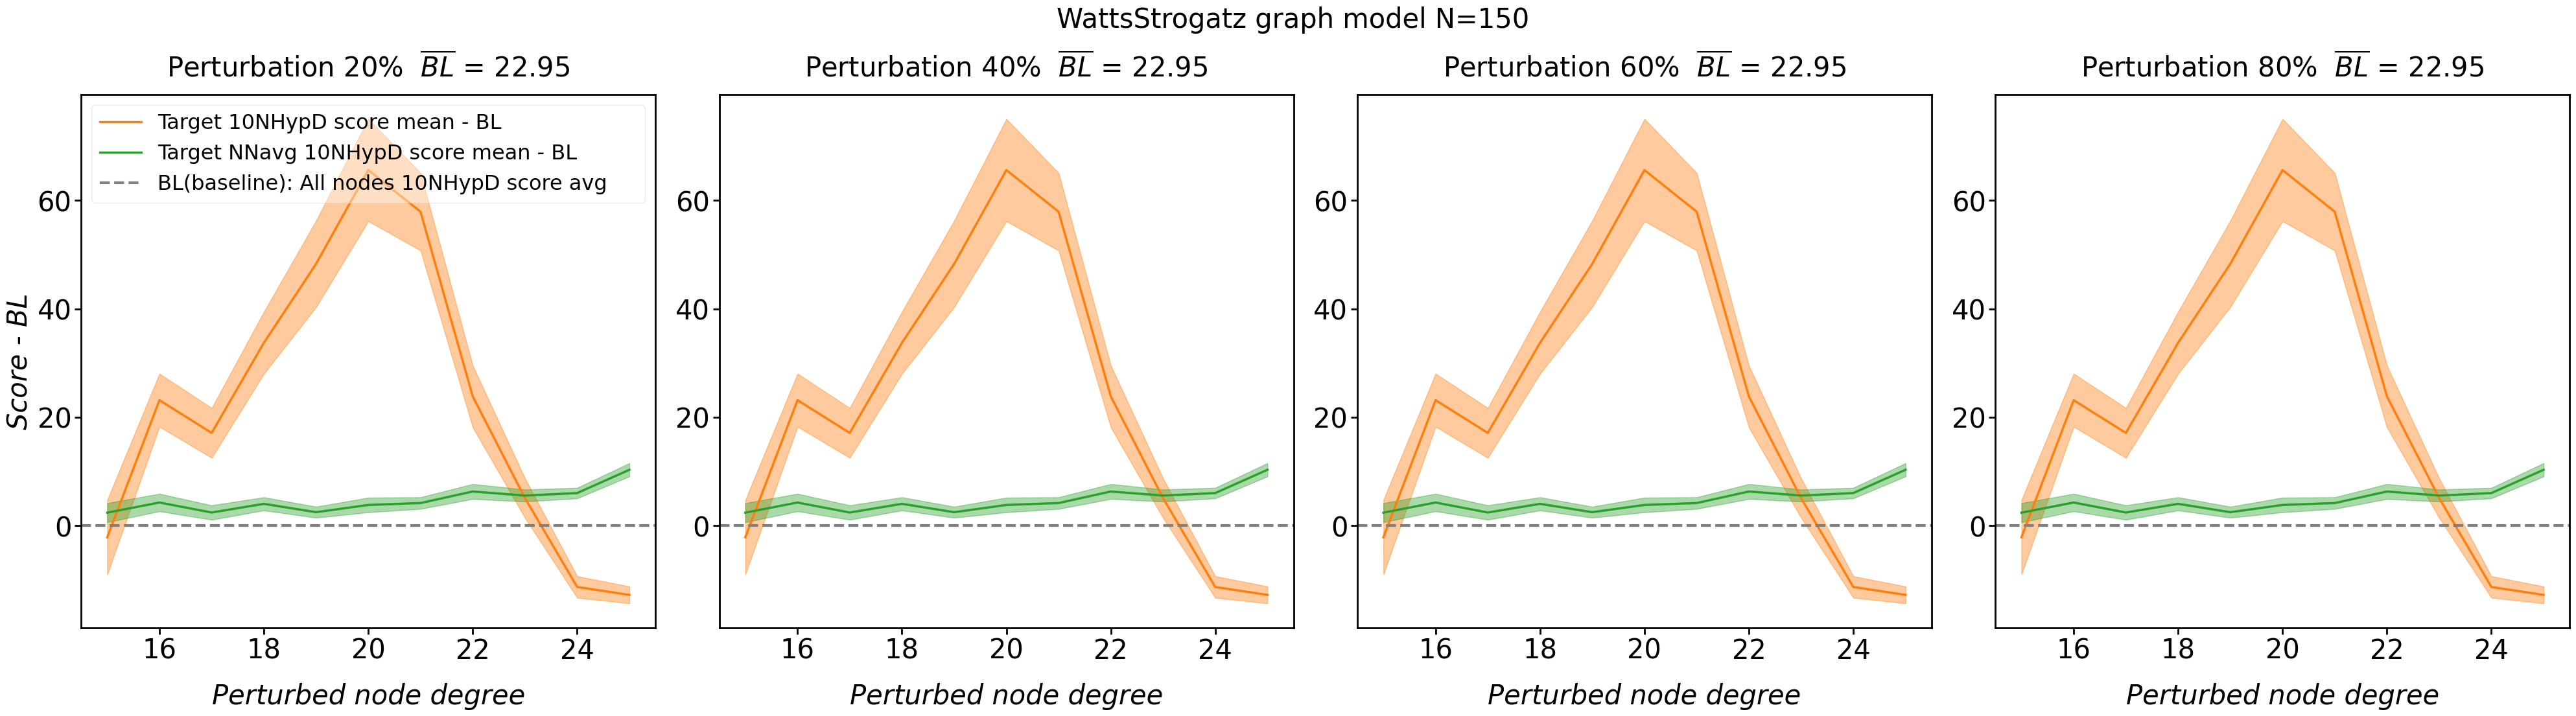

In [35]:
if domain == 'degree':
    
    fig =plt.figure(figsize = (40,11))
    plt.rcParams['axes.linewidth']=2.0
    fig.suptitle('%s graph model N=%i'%(model,N), fontsize=30, y=1.0005)

    for i,m in enumerate(mag_arr):

        alpha = alpha_dict[m]
        
        # Creation of the axis
        ax = fig.add_subplot(1,4,i+1)
        
        # the x
        degree_order = np.argsort(list(degreeXscore_global))
        degrees = np.sort(list(degreeXscore_global))
        ld = len(degrees)
        
        # y and dy
        ref = list(degreeXscore_global.values())
        ref_avg = [np.mean(ref[i]) for i in range(ld)]
        ref_avg_avg = np.mean(ref_avg)
        
        target_Score_values = list(degreeXscore_target.values())
        target_Score_avg = np.array([np.mean(target_Score_values[i]-ref[i]) for i in range(ld)])[degree_order] # target score - ref
        target_Score_ci = np.array([st.t.interval(confidence=0.95, df=len(target_Score_values[i]-ref[i])-1, 
                                            loc=np.mean(target_Score_values[i]-ref[i]), 
                                            scale=st.sem(target_Score_values[i]-ref[i])) for i in range(ld)])[degree_order]
        
        ax.plot(degrees, target_Score_avg,'-', linewidth=2.5, markersize=8, alpha=1, color='tab:orange', markeredgecolor=colors[0], markerfacecolor='white', markeredgewidth=2, label='Target %iNHypD score mean - BL'%k)
        ax.fill_between(degrees, target_Score_ci[:,0], target_Score_ci[:,1], alpha=0.4, color='tab:orange')
        
        target2_Score_values = list(degreeXscore_target2.values())
        target2_Score_avg = np.array([np.mean(target2_Score_values[i]-ref[i]) for i in range(ld)])[degree_order] # target score - ref
        target2_Score_ci = np.array([st.t.interval(confidence=0.95, df=len(target2_Score_values[i]-ref[i])-1, 
                                            loc=np.mean(target2_Score_values[i]-ref[i]), 
                                            scale=st.sem(target2_Score_values[i]-ref[i])) for i in range(ld)])[degree_order]

        
        ax.plot(degrees, target2_Score_avg,'-', linewidth=2.5, markersize=8, alpha=1, color='tab:green', markeredgecolor=colors[1], markerfacecolor='white', markeredgewidth=2, label='Target NNavg %iNHypD score mean - BL'%k)
        ax.fill_between(degrees, target2_Score_ci[:,0], target2_Score_ci[:,1], alpha=0.4, color='tab:green')

        ax.axhline(y=0, linestyle='--', linewidth='3', color='gray', label='BL(baseline): All nodes %iNHypD score avg'%k)
        
        # Parameters
        
        ax.set_xlabel(r'Perturbed node degree', style = 'italic', fontsize = 30, labelpad=20)
    
        if i==0:
            ax.set_ylabel(r'Score - BL', style = 'italic', fontsize = 30)
            ax.legend(fontsize = 23, ncol=1, loc='upper center', fancybox=True, framealpha=0.4, mode='expand')
    
        ax.tick_params(axis = 'x', which = 'both',labelsize = 30, width = 2, length = 7 ) #ax1.tick_params(axis='y', labelcolor=color)
        ax.tick_params(axis = 'y', which = 'both' ,labelsize = 30, width = 2, length = 7 )
    
        ax.set_title('Perturbation ' + str(int(m*100)) + '%' +  r'  $\overline{BL}$ = %.2f'%(ref_avg_avg) , fontsize = 30, pad=20)
        #ax.set_xscale('log')
    
    fig.tight_layout()
    
    #plt.savefig(media_folder+'/degreeXscoresDiff_allMags_%s_dis_nG%i.pdf'%(model,n_G))
    plt.show()    

### 6.2 Clustering class plot

In [36]:
if domain == 'clustering1' or domain == 'clustering2': 

    fig =plt.figure(figsize = (40,11))
    plt.rcParams['axes.linewidth']=2.0
    fig.suptitle('%s graph model N=%i'%(model,N), fontsize=30, y=1.0005)

    for i,m in enumerate(mag_arr): 

        alpha = alpha_dict[m]
        
        # Creation of the axis
        ax = fig.add_subplot(1,4,i+1)
        
        # the x
        clustering_order = np.argsort(list(clusteringXscore_global))
        clusterings = np.sort(list(clusteringXscore_global))/100 #for clustering_int2
        ld = len(clusterings)
        print(clusterings)

        # y and dy
        ref = list(clusteringXscore_global.values())
        ref_avg = [np.mean(ref[i]) for i in range(ld)]
        ref_avg_avg = np.mean(ref_avg)
        
        target_Score_values = list(clusteringXscore_target.values())
        target_Score_avg = np.array([np.mean(target_Score_values[i]-ref[i]) for i in range(ld)])[clustering_order] # target score - ref
        target_Score_ci = np.array([st.t.interval(confidence=0.95, df=len(target_Score_values[i]-ref[i])-1, 
                                            loc=np.mean(target_Score_values[i]-ref[i]), 
                                            scale=st.sem(target_Score_values[i]-ref[i])) for i in range(ld)])[clustering_order]
        
        ax.plot(clusterings, target_Score_avg,'-', linewidth=2.5, markersize=8, alpha=1, color='tab:orange', markeredgecolor=colors[0], markerfacecolor='white', markeredgewidth=2, label='Target %iNHypD score mean - BL'%k)
        ax.fill_between(clusterings, target_Score_ci[:,0], target_Score_ci[:,1], alpha=0.4, color='tab:orange')
        
        target2_Score_values = list(clusteringXscore_target2.values())
        target2_Score_avg = np.array([np.mean(target2_Score_values[i]-ref[i]) for i in range(ld)])[clustering_order] # target score - ref
        target2_Score_ci = np.array([st.t.interval(confidence=0.95, df=len(target2_Score_values[i]-ref[i])-1, 
                                            loc=np.mean(target2_Score_values[i]-ref[i]), 
                                            scale=st.sem(target2_Score_values[i]-ref[i])) for i in range(ld)])[clustering_order]

        
        ax.plot(clusterings, target2_Score_avg,'-', linewidth=2.5, markersize=8, alpha=1, color='tab:green', markeredgecolor=colors[1], markerfacecolor='white', markeredgewidth=2, label='Target NNavg %iNHypD score mean - BL'%k)
        ax.fill_between(clusterings, target2_Score_ci[:,0], target2_Score_ci[:,1], alpha=0.4, color='tab:green')

        ax.axhline(y=0, linestyle='--', linewidth='3', color='gray', label='BL(baseline): All nodes %iNHypD score avg'%k)
        
        # Parameters
        
        ax.set_xlabel(r'Perturbed node clustering', style = 'italic', fontsize = 30, labelpad=20)
    
        if i==0:
            ax.set_ylabel(r'Score - BL', style = 'italic', fontsize = 30)
            ax.legend(fontsize = 23, ncol=1, loc='upper center', fancybox=True, framealpha=0.4, mode='expand')
    
        ax.tick_params(axis = 'x', which = 'both',labelsize = 30, width = 2, length = 7 ) #ax1.tick_params(axis='y', labelcolor=color)
        ax.tick_params(axis = 'y', which = 'both' ,labelsize = 30, width = 2, length = 7 )
    
        ax.set_title('Perturbation ' + str(int(m*100)) + '%' +  r'  $\overline{BL}$ = %.2f'%(ref_avg_avg) , fontsize = 30, pad=20)
        #ax.set_xscale('log')

    
    fig.tight_layout()
    
    #plt.savefig(media_folder+'/clusteringXscoresDiff_allMags_%s_dis_nG%i.pdf'%(model,n_G))
    plt.show() 